In [14]:
from OpOp.Model import Sersic, NFW, NbodyModel, Tbetamodel
import numpy as np
import matplotlib.pyplot as plt

In [2]:
import inspect
from OpOp.Model import Multimodel, NbodyModel
print(inspect.signature(Multimodel.__init__))
print(inspect.signature(NbodyModel.__init__))
print(inspect.getdoc(Multimodel))

(self, *args)
(self, components, dff=<function df_isotropic at 0x11045ac00>, Ngrid=512, xmin=0.002, xmax=200, kind='log', r_physic=False)
None


In [2]:
star = Sersic(m=1.0, rc=0.15, Mtot=1e7)   # n=1, scale length 0.15 kpc, 1e7 Msun

r = np.logspace(-2, 0.7, 200)             # kpc
rho  = star.dens(r)       # Msun/kpc^3
M    = star.mass(r)       # enclosed mass, Msun
phi  = star.pot(r)        # (km/s)^2
vc   = np.sqrt(star.G * M / r)   # circular velocity, km/s

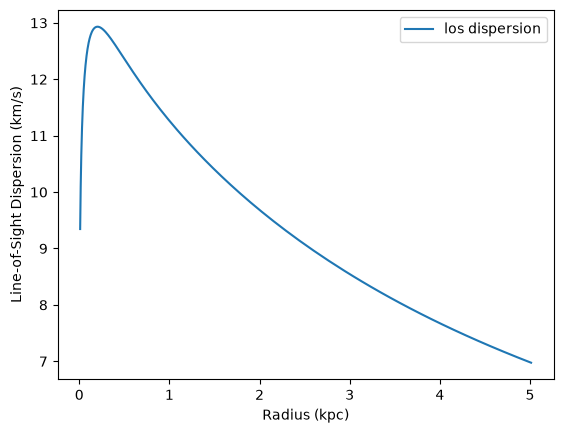

In [3]:
from scipy.optimize import brentq
r_half = brentq(lambda x: star.mass(x) - 0.5e7, 1e-3, 10)

from scipy.integrate import quad

Mvir=1e10
rtrunc_dm=40

halo = NFW(Mc=Mvir, c=None, rt=None)   # check its signature: M200/rs or c, in the same units

def Mtot(r): return star.mass(r) + halo.mass(r)

def sigma2(r):
    f = lambda x: star.dens(x) * star.G * Mtot(x) / x**2
    val, _ = quad(f, r, 50)       # integrate to a large radius
    return val / star.dens(r)     # (km/s)^2, 1D dispersion

sig_los_like = np.sqrt([sigma2(x) for x in r])
plt.plot(r, sig_los_like, label='los dispersion')
plt.xlabel('Radius (kpc)')
plt.ylabel('Line-of-Sight Dispersion (km/s)')
plt.legend()
plt.show()

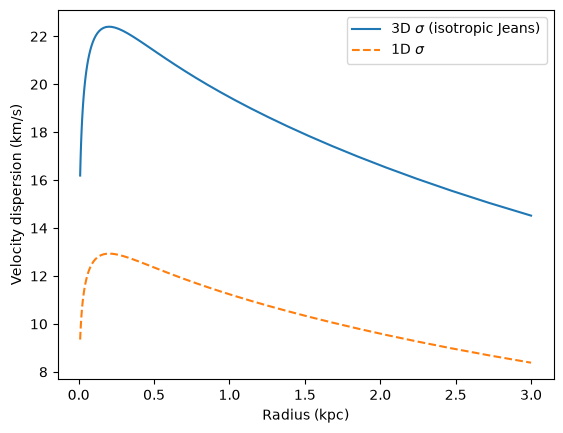

In [33]:
from scipy.integrate import quad

nat  = NFW(Mc=1e10, c=None, rt=None)   # natural untruncated halo, c from the c(M) relation
rs   = nat.rscale
M04  = nat.mass(0.4)                   # inner mass to preserve

halo_trunc = Tbeta(rc=rs, Ms=M04, rs=0.4, gamma=1, beta=3, rt=10.0)

def Mtot(x):
    return star.mass(x) + halo_trunc.mass(x)

def sigma2(R):
    f = lambda x: float(star.dens(x) * star.G * Mtot(x) / x**2)
    val, _ = quad(f, R, 50)
    return val / float(star.dens(R))          # (km/s)^2

rgrid = np.logspace(-2, np.log10(3), 60)       # kpc, new name so it can't be overwritten
sig1d = np.sqrt([sigma2(x) for x in rgrid])

plt.plot(rgrid, sig1d * np.sqrt(3), label=r'3D $\sigma$ (isotropic Jeans)')
plt.plot(rgrid, sig1d, '--', label=r'1D $\sigma$')
plt.xlabel('Radius (kpc)')
plt.ylabel('Velocity dispersion (km/s)')
plt.legend()
plt.show()

In [34]:
#Nbody Model star
model_star={'type':1, 'model':star,'npart':int(1e4)}
#Nbody Model DM
model_dm={'type':2, 'model':halo_trunc,'npart':int(5e5)}
#Final model
a=NbodyModel([model_star,model_dm])
#Generate
p=a.generate(use_c=True, po=None,vo=None,mq=70,set_vel=True)

***Generate ICS: Start***
-Component id:0 type:1 Npart=10000
     Generate Positions:      Done
     Generate Velocities:      Done
     Done in 0.179
-Component id:1 type:2 Npart=500000
     Generate Positions:      Done
     Generate Velocities:      Done
     Done in 0.598


In [35]:
##Save Nbody model to FVFPS input file 
#Use the write_snap method from OpOp.io
from OpOp.io import write_snap
write_snap(p,filename='out_dwarf_trunc.bin',kind='fvfps')
#The main write_snap parameters are:
# particles: objected created from a NbodyModel 
# filename: filename for the saved output 
# kind: format for the outpt generation

##Generate the input file for fvfps 
#Use the function write_icparam_fvfps from OpOp.io 
from OpOp.io import write_icparam_fvfps
#The parameters are 
#theta (default 0.5)
#epsc  (default 0.01)
#isoft (default 1)
#noutput (default 1)
#iene (default 120)
#The above parameters are equivalent to the fvfps parameter (see the documentation) 
#The other parameters are 
#tmax (default 1) maximum time of the simulation in Gyr
#max_dt (dfault 0.001) largest allowed value of the time step  in Gyr
#poscm, Cartesian coordinates (x,y,z) of the centre of mass  of the Nbody realisation  (default (0,0,0)) in kpc
#velcm, Cartesian velocity coordinates (vx,vy,vz) of the centre of mass of the starting point of the Nbody realisation  (default (0,0,0)) in km/s
#epotential (default 'J95') external potential model to use 
###The output will be saved in the finel input.data that can be used directly as input parameter file for fvfps
###Notice that the method tranform the input times in Gyr directly in Nbody units, so inside input.data tmax and max_dt will not the same of the value used to call the function
tmax=1
dt=0.001
write_icparam_fvfps(tmax=tmax, max_dt=dt, epotential='J95', poscm=(0,0,0), velcm=(0,0,0))


%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
Reading particle data from out_dwarf_trunc.bin......
Done

%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
Sorting by Id
Sorted


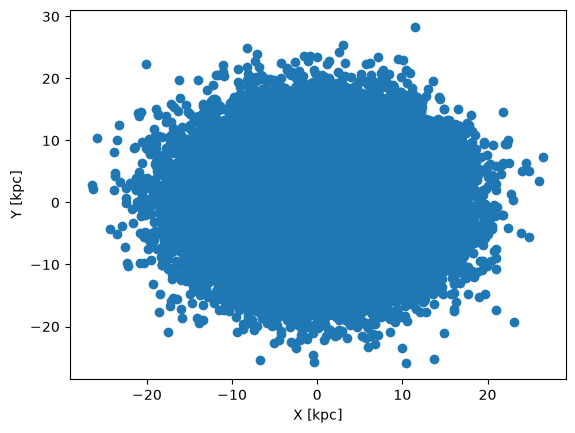

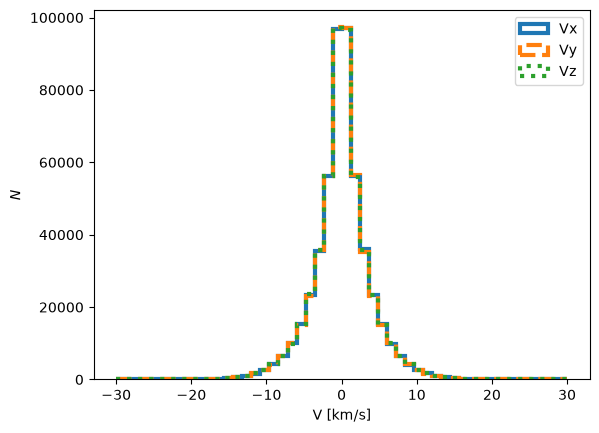

Id vector [     0      1      2 ... 509997 509998 509999]
type vector [1 1 1 ... 2 2 2]


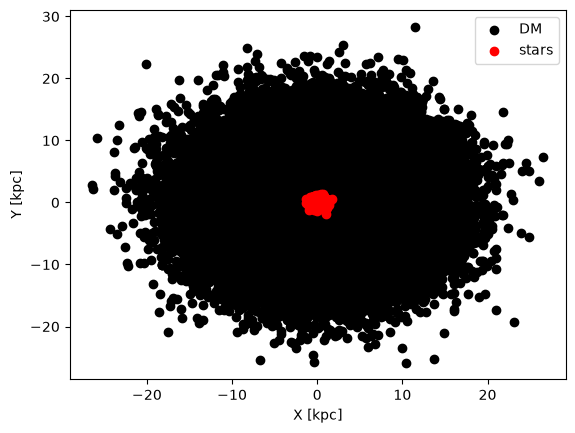

Centre of mass [kpc] [-0.00658588 -0.00503412 -0.0039304 ]
Centre of mass velocity [km/s] [-0.10634011  0.00181044  0.02924074]


/Users/olgahinke/OpOpGadget/venv311/lib/python3.11/site-packages/numpy/_core/_methods.py:219: RuntimeWarning: Degrees of freedom <= 0 for slice
  ret = _var(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/Users/olgahinke/OpOpGadget/venv311/lib/python3.11/site-packages/numpy/_core/_methods.py:178: RuntimeWarning: invalid value encountered in divide
  arrmean = um.true_divide(arrmean, div, out=arrmean,
/Users/olgahinke/OpOpGadget/venv311/lib/python3.11/site-packages/numpy/_core/_methods.py:211: RuntimeWarning: invalid value encountered in divide
  ret = ret.dtype.type(ret / rcount)


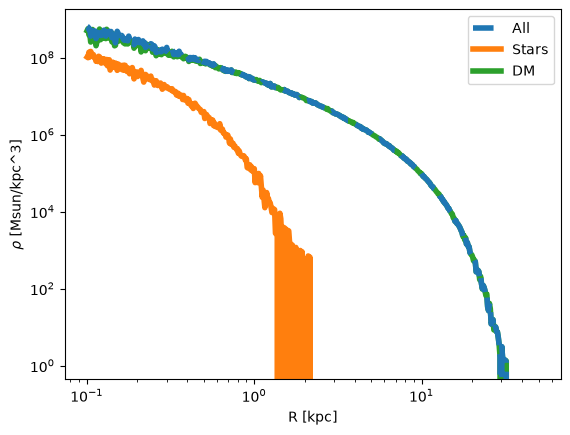

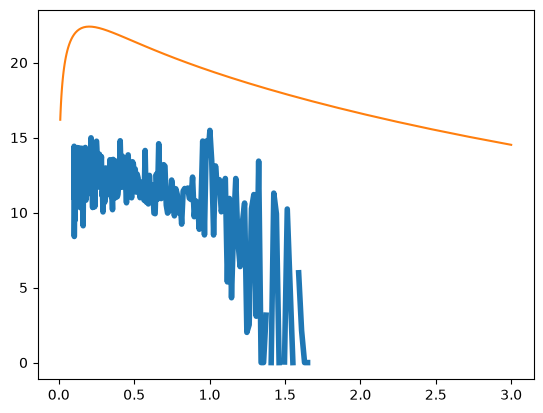

In [36]:
##Load binary output from fvfps 
#To load a binary output file from fvfps just use the method load_snap from OpOp.io 
from OpOp.io import load_snap
#the only parameter needed is filename, i.e. the complete path to the ouput file to read
pnbody=load_snap(filename="out_dwarf_trunc.bin")

#The output file is saved in a Particles objects (the same generated by the method generate of the class Nbody model)
#Give a look to the class Particles in the file partile_src/particle.pyt 

#Suggestion-1, to access the position just call the member Pos, it is a numpy array with dimensions N,3 where N is the 
#number of particles: each row rapresent a particle and each column a Cartsian coordinate x,y,z
import matplotlib.pyplot as plt
X=pnbody.Pos[:,0]
Y=pnbody.Pos[:,1]

plt.scatter(X,Y)
plt.xlabel("X [kpc]")
plt.ylabel("Y [kpc]")
plt.show()

#Suggestion-2, similarly to Pos, the member Vel contains the cartesian velocity of the particles 
Vx=pnbody.Pos[:,0]
Vy=pnbody.Pos[:,1]
Vz=pnbody.Pos[:,2]
plt.hist(Vx,histtype="step",bins=50,lw=3, range=(-30,30),label="Vx")
plt.hist(Vy,histtype="step",bins=50,lw=3, range=(-30,30),ls="dashed",label="Vy")
plt.hist(Vz,histtype="step",bins=50,lw=3, range=(-30,30),ls="dotted",label="Vz")
plt.xlabel("V [km/s]")
plt.ylabel("$N$")
plt.legend()
plt.show()

#Suggestion-3, the member Id is a 1D array containing the ID of all the particles, while the member Type contains a list of integer
#reporting the particle type (it depends on how you setup the models with Nbody, in the example above type 1 are stars and type 2 are DM)
print("Id vector",pnbody.Id)
print("type vector",pnbody.Type)
idstars=pnbody.Type==1
idDM=pnbody.Type==2
plt.scatter(X[idDM],Y[idDM],c="k",label="DM")
plt.scatter(X[idstars],Y[idstars],c="red",label="stars")
plt.legend()
plt.xlabel("X [kpc]")
plt.ylabel("Y [kpc]")
plt.show()

#Suggestion-4, the classes Analysis and Profile and their methods from OpOp.analysis can be used to 
#automatise some analysis: e.g. searching the centre of mass or producing a radial profile.
#For example:
## Estimating the centre of mass:
from OpOp.analysis import Analysis
a_tmp = Analysis(particles=pnbody, safe=True, auto_centre=False, iter=True, single=False)
com,vcom=a_tmp.com()
print("Centre of mass [kpc]",com)
print("Centre of mass velocity [km/s]",vcom)

##Producing a density profile
from OpOp.analysis import Profile

prof=Profile(pnbody,center=True,iter=True,xmin=1e-1,xmax=50)
#Total profile
arr = prof.dens()[0]
r=arr[:,0]
dens=arr[:,1]
plt.plot(r,dens,label="All",ls="dashed",lw=4,zorder=1000)

#Stellar profile 
profstar=Profile(pnbody,center=True,iter=True,xmin=1e-1,xmax=50,type=1)
arr = profstar.dens()[0]
sig_arr= profstar.vdisp3d()[0]
r=arr[:,0]
dens=arr[:,1]
sig = sig_arr[:,1]
plt.plot(r,dens,label="Stars",lw=4)

#DM profile 
profDM=Profile(pnbody,center=True,iter=True,xmin=1e-1,xmax=50,type=2)
arr = profDM.dens()[0]
r=arr[:,0]
dens=arr[:,1]
plt.plot(r,dens,label="DM",lw=4)

plt.legend()
plt.xlabel("R [kpc]")
plt.ylabel("$\\rho$ [Msun/kpc^3]")
plt.xscale("log")
plt.yscale("log")
plt.show()

sig_stars = profstar.vdisp3d()[0]
plt.plot(r, sig, label="Stars", lw=4)
plt.plot(rgrid, sig1d * np.sqrt(3), label=r'3D $\sigma$ (isotropic Jeans)')
#For additional examples about the exploitation of the class Analysis and Profile give a look to the example Python script in scrip/analyses_sims.py

/var/folders/w3/j46bj_hn2wsbrfr2354jsn780000gv/T/ipykernel_51592/2629211611.py:9: RuntimeWarning: invalid value encountered in divide
  beta  = 1 - (st[:, 1]**2 + sp[:, 1]**2) / (2 * sr[:, 1]**2)   # anisotropy


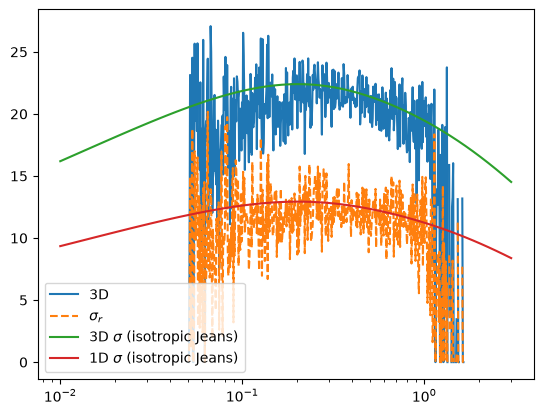

In [49]:
p = Profile(pnbody, center=True, iter=True, xmin=5e-2, xmax=2, type=1, spherical_cord=True)

sr   = p.vdisp3d(ax='r')[0]       # sigma_r
st   = p.vdisp3d(ax='theta')[0]   # sigma_theta
sp   = p.vdisp3d(ax='phi')[0]     # sigma_phi

r = sr[:, 0]
sig3d = np.sqrt(sr[:, 1]**2 + st[:, 1]**2 + sp[:, 1]**2)
beta  = 1 - (st[:, 1]**2 + sp[:, 1]**2) / (2 * sr[:, 1]**2)   # anisotropy

plt.plot(r, sig3d, label='3D')
plt.plot(r, sr[:, 1], '--', label=r'$\sigma_r$')
plt.plot(rgrid, sig1d * np.sqrt(3), label=r'3D $\sigma$ (isotropic Jeans)')
plt.plot(rgrid, sig1d , label=r'1D $\sigma$ (isotropic Jeans)')
plt.xscale('log'); plt.legend(); plt.show()

In [37]:
coords = pnbody.Pos
vels = pnbody.Vel
mass = pnbody.Mass

output_file = "/Users/olgahinke/dwarfs/dwarf_opop_trunc.txt"

n = len(mass)
with open(output_file, "w") as f:
    for i in range(n):
        f.write(
            f"{coords[i,0]:.6f},"
            f"{coords[i,1]:.6f},"
            f"{coords[i,2]:.6f},"
            f"{vels[i,0]:.6f},"
            f"{vels[i,1]:.6f},"
            f"{vels[i,2]:.6f},"
            f"{mass[i]:.6e}\n"
        )
print(f"Writing {n:,} particles...")

Writing 510,000 particles...
